  show_id     type             title   director                     cast  \
0      s1    Movie  The Last Journey  A. Sharma                      NaN   
1      s2  TV Show   City Detectives    M. Khan                      NaN   
2      s3    Movie   Ocean of Dreams  L. Martin  Emma Stone, Daniel Reed   
3      s4  TV Show    Hidden Academy        NaN    Mia Clark, Noah James   
4      s5    Movie  Beyond the Hills   P. Patel    Arjun Mehta, Neha Rao   

          country         date_added  release_year rating   duration  \
0           India  November 24, 2023          2021  TV-14    112 min   
1           India     April 23, 2025          2020  TV-MA  2 Seasons   
2   United States     March 23, 2021          2019  PG-13     98 min   
3  United Kingdom      June 20, 2019          2022  TV-PG   1 Season   
4           India  November 20, 2020          2018     PG    104 min   

                                listed_in  \
0            Dramas, International Movies   
1  Crime TV Shows, I

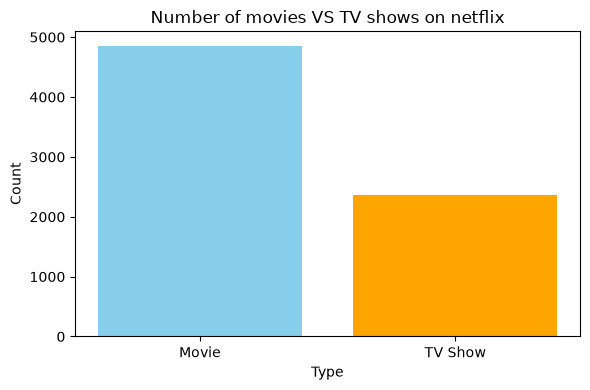

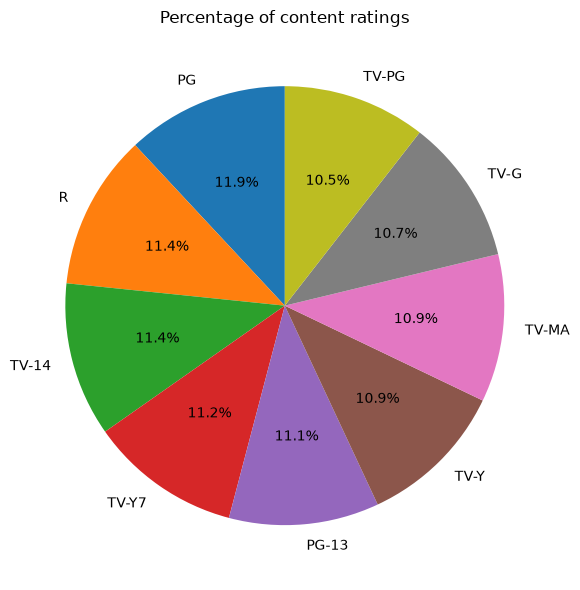

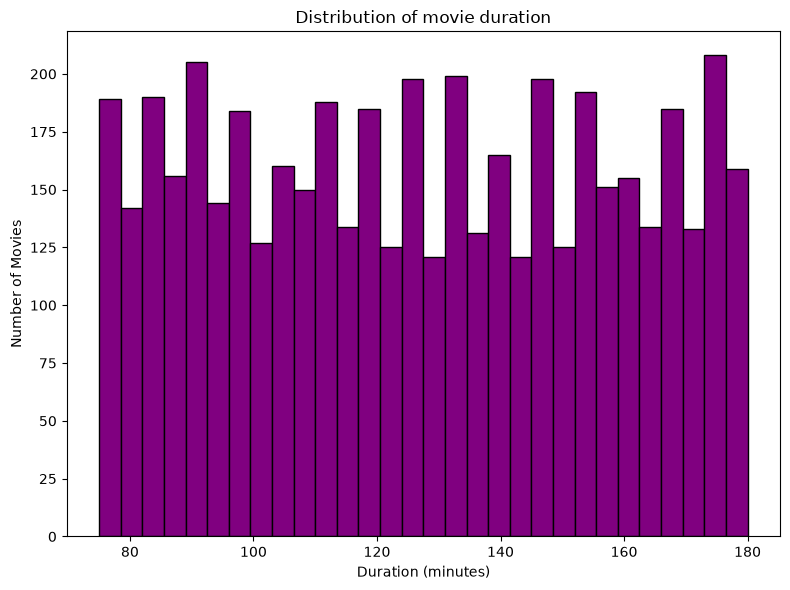

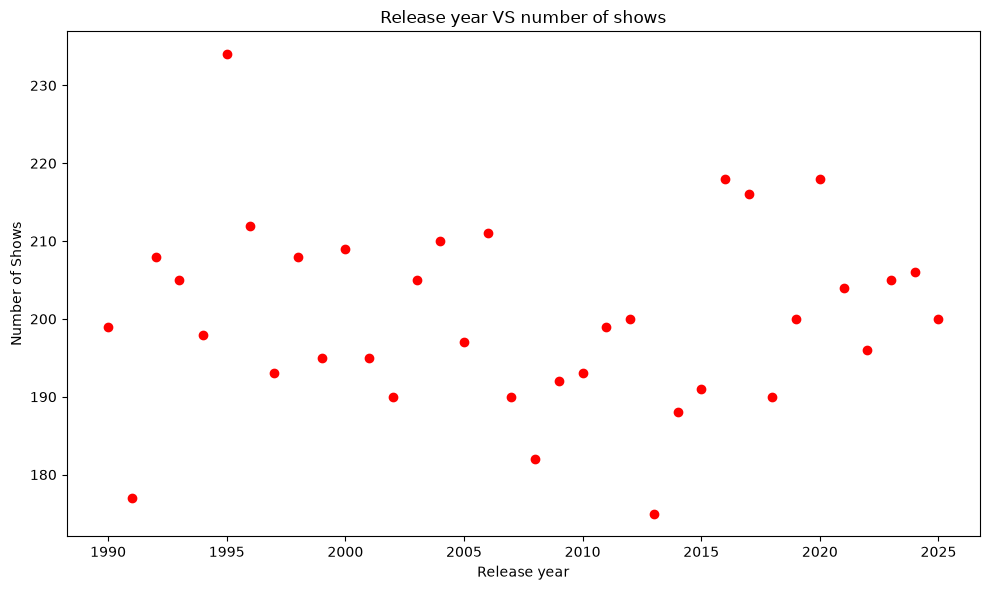

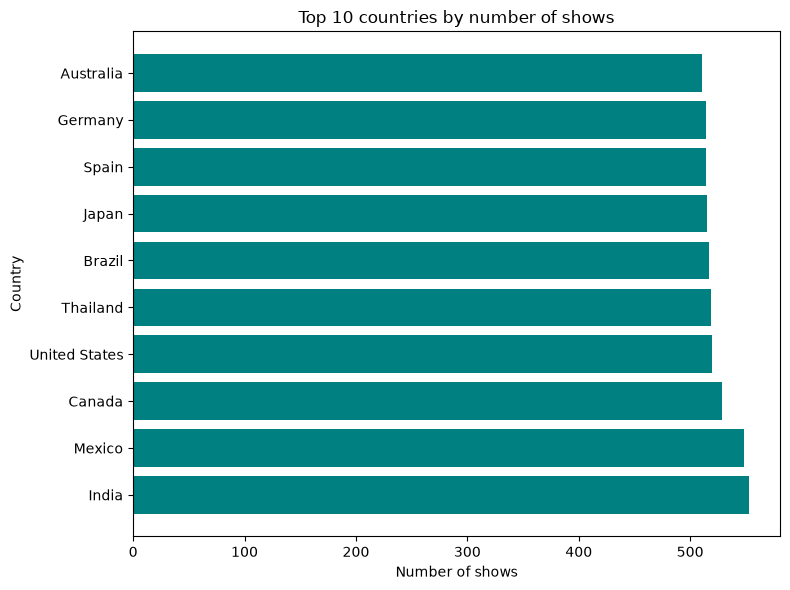

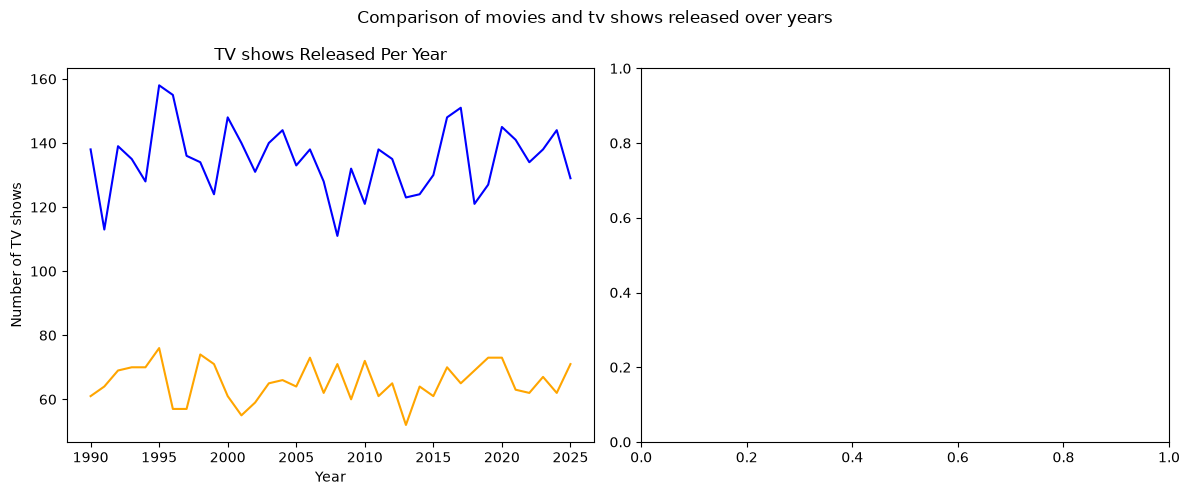

In [9]:
#import os 
#os.getcwd()

#step-1 import libraries
import pandas as pd 
import matplotlib.pyplot as plt

#load the data
df = pd.read_csv('C:\\Users\\ACSS\\Desktop\\Data visualization\\netflix_practice_8007_rows.csv')
print(df.head())

#clean data
df = df.dropna(subset=['type','release_year','rating','country','duration'])

type_counts = df['type'].value_counts()
plt.figure(figsize=(6,4))
plt.bar(type_counts.index, type_counts.values, color=['skyblue', 'orange'])
plt.title('Number of movies VS TV shows on netflix')
plt.xlabel('Type')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('movies_vs_tvshows.png')
plt.show()

rating_counts = df['rating'].value_counts()
plt.figure(figsize=(8,6))
plt.pie(rating_counts, labels=rating_counts.index, autopct='%1.1f%%',startangle=90)
plt.title('Percentage of content ratings')
plt.tight_layout()
plt.savefig('content_Ratings_pie.png')
plt.show()

movie_df = df[df['type'] == 'Movie'].copy()
movie_df['duration_int'] = movie_df['duration'].str.replace('min','').astype(int)

plt.figure(figsize=(8,6))
plt.hist(movie_df['duration_int'], bins=30, color='purple', edgecolor='black')
plt.title('Distribution of movie duration')
plt.xlabel('Duration (minutes)')
plt.ylabel('Number of Movies')
plt.tight_layout()
plt.savefig('movie_duration_histogram.png')
plt.show()

release_counts = df['release_year'].value_counts().sort_index()
plt.figure(figsize=(10,6))
plt.scatter(release_counts.index, release_counts.values, color='red')
plt.title('Release year VS number of shows')
plt.xlabel('Release year')
plt.ylabel('Number of Shows')
plt.tight_layout()
plt.savefig('release_year_scatter.png')
plt.show()

country_counts = df['country'].value_counts().head(10)
plt.figure(figsize=(8,6))
plt.barh(country_counts.index, country_counts.values, color='teal')
plt.title('Top 10 countries by number of shows')
plt.xlabel('Number of shows')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig('top10_countries.png')
plt.show()

content_by_year = df.groupby(['release_year','type']).size().unstack().fillna(0)

fig, ax = plt.subplots(1,2, figsize=(12,5))

#first subplot:movies
ax[0].plot(content_by_year.index, content_by_year['Movie'], color='blue')
ax[0].set_title('Movie Released Per Year')
ax[0].set_xlabel('Year')
ax[0].set_ylabel('Number of movies')

#second subplot:TV shows
ax[0].plot(content_by_year.index, content_by_year['TV Show'], color='orange')
ax[0].set_title('TV shows Released Per Year')
ax[0].set_xlabel('Year')
ax[0].set_ylabel('Number of TV shows')

fig.suptitle('Comparison of movies and tv shows released over years')

plt.tight_layout()
plt.savefig('movies_tv_shows_comparsion.png')
plt.show()
